# Next-hour burn probabilities from nonnegative learned kernels

This runnable demonstration loads the supported exponential 3×3, 5×5, 7×7, and 9×9 legacy-kernel checkpoints selected in the completed `20261010_categorical_balanced_benchmark` run and one FishCreek snapshot. The 5×5 checkpoint is the central `wildfire.paths.DEFAULT_CHECKPOINT`. These weights differ from the older saved demonstrations. It displays predictions over every cell with adequate input coverage, including known-unburned neighborhoods with no burned source cells. Such complete neighborhoods have exactly zero probability because the model has no spontaneous-ignition term.

**Metrics use only currently unburned cells with at least one current burned neighbor within the kernel.** Native cohorts differ by kernel and describe each support separately. The comparison table uses their intersection so all models are scored on exactly the same targets. This single snapshot is descriptive and does not select a model or replace the held-out multi-fire experiment.

The target is retrospective arrival-time reconstruction inside a final fire perimeter. It is not an independently observed hourly burn map. Gray values remain unknown. Historical saved reports and outputs retain their original models.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'pyproject.toml').is_file() and (p / 'wildfire').is_dir()), None)
assert ROOT is not None, "Start Jupyter from the workspace or one of its subdirectories."
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from wildfire import load_model
from wildfire.metrics import probability_metrics
from wildfire.paths import DEFAULT_CHECKPOINT

torch.set_num_threads(4)
RUNS = ROOT / 'runs'
DATA_ROOT = ROOT / 'data/environment'
KERNELS = (3, 5, 7, 9)
EVENT = "WY-BTF-002416_FishCreek"
CUTOFF = "2024-08-23T00:00:00Z"
BENCHMARK = RUNS / "20261010_categorical_balanced_benchmark"
selected_candidate_ids = {
    3: "k3_legacy_02_lr0.05_constant",
    5: "k5_legacy_02_lr0.1_warmup_cosine",
    7: "k7_legacy_02_lr0.05_warmup_cosine",
    9: "k9_legacy_02_lr0.1_warmup_cosine",
}
checkpoints = {k: BENCHMARK / "candidates" / selected_candidate_ids[k] / "checkpoint.pt"
               for k in KERNELS}
checkpoints[5] = DEFAULT_CHECKPOINT
assert all(path.is_file() for path in checkpoints.values())
models = {k: load_model(checkpoints[k]) for k in KERNELS}
assert len({model.channel_names for model in models.values()}) == 1
with models[5].load_data(DATA_ROOT, events=[EVENT], sequence_length=1,
                         time_range=(CUTOFF, CUTOFF)) as dataset:
    assert len(dataset) == 1
    sample = dataset[0]
print(EVENT, CUTOFF, sample["burned_area"].shape)

WY-BTF-002416_FishCreek 2024-08-23T00:00:00Z torch.Size([1, 1, 103, 73])


For target cell $i$, burned-state indicator $B_i$, environmental field $E$, and kernel offsets $\delta$, the frozen one-hour predictor is

$$\lambda_i=\sum_{\delta\ne0}k_{i,\delta}(E)B_{i+\delta},\quad k_{i,\delta}(E)\ge0,\quad p_i=(1-B_i)(1-e^{-\lambda_i}).$$

The center coefficient is zero. Rates are in h⁻¹; $p_i$ is a probability. Current cumulative burning supplies sources and does not identify an active flame front. Inference reads current inputs and masks only. The following cell reads retrospective arrival information separately to define the evaluation target.

In [2]:
results = {k: model.predict_sample_details(sample) for k, model in models.items()}
probability = {k: result.probability.numpy()[0, 0] for k, result in results.items()}
prediction_valid = {k: result.valid.numpy()[0, 0] for k, result in results.items()}
burned = sample["burned_area"][0, 0].numpy()
burned_valid = sample["burned_area_valid"][0, 0].numpy()
arrival = sample["arrival_hours"][0].numpy()
arrival_valid = sample["arrival_valid"][0].numpy()
elapsed = float(sample["elapsed_hours"][0])
target = ((arrival > elapsed) & (arrival <= elapsed + 1)).astype(np.float32)

burned_tensor = sample["burned_area"].float()
neighbor_count = {}
cohorts = {}
for k in KERNELS:
    footprint = torch.ones(1, 1, k, k)
    footprint[0, 0, k // 2, k // 2] = 0
    neighbor_count[k] = F.conv2d(burned_tensor, footprint, padding=k // 2)[0, 0].numpy()
    cohorts[k] = (prediction_valid[k] & burned_valid & arrival_valid
                  & (burned == 0) & (neighbor_count[k] > 0))
shared = np.logical_and.reduce([cohorts[k] for k in KERNELS])
assert shared.any(), "This snapshot has no shared contact-conditioned evaluation targets."
rows = []
for k in KERNELS:
    for scope, selected in (("native support (descriptive)", cohorts[k]),
                            ("shared support (comparison)", shared)):
        metrics = probability_metrics(target[selected], probability[k][selected],
                                      np.ones(int(selected.sum())), neighbor_count[k][selected])
        rows.append({"kernel": k, "scope": scope, **metrics})
metrics = pd.DataFrame(rows)
display(metrics[["kernel", "scope", "sample_count", "positive_sample_count", "brier",
                 "average_precision", "roc_auc", "exact_negative_log_likelihood_mean"]])
# The complete raster has one row per available cell, so these descriptive
# snapshot metrics use equal weights; the multi-fire sampled caches use IPW.

,kernel,scope,sample_count,positive_sample_count,brier,average_precision,roc_auc,exact_negative_log_likelihood_mean
0,3,native support (descriptive),39,1,0.025351,0.071429,0.657895,0.117374
1,3,shared support (comparison),14,0,0.002461,NaN,NaN,0.044916
2,5,native support (descriptive),34,1,0.028574,0.083333,0.666667,0.120622
3,5,shared support (comparison),14,0,0.003225,NaN,NaN,0.049735
4,7,native support (descriptive),22,1,0.043090,0.125000,0.666667,0.174760
5,7,shared support (comparison),14,0,0.001897,NaN,NaN,0.039925
6,9,native support (descriptive),16,0,0.001300,NaN,NaN,0.036525
7,9,shared support (comparison),14,0,0.001339,NaN,NaN,0.037097


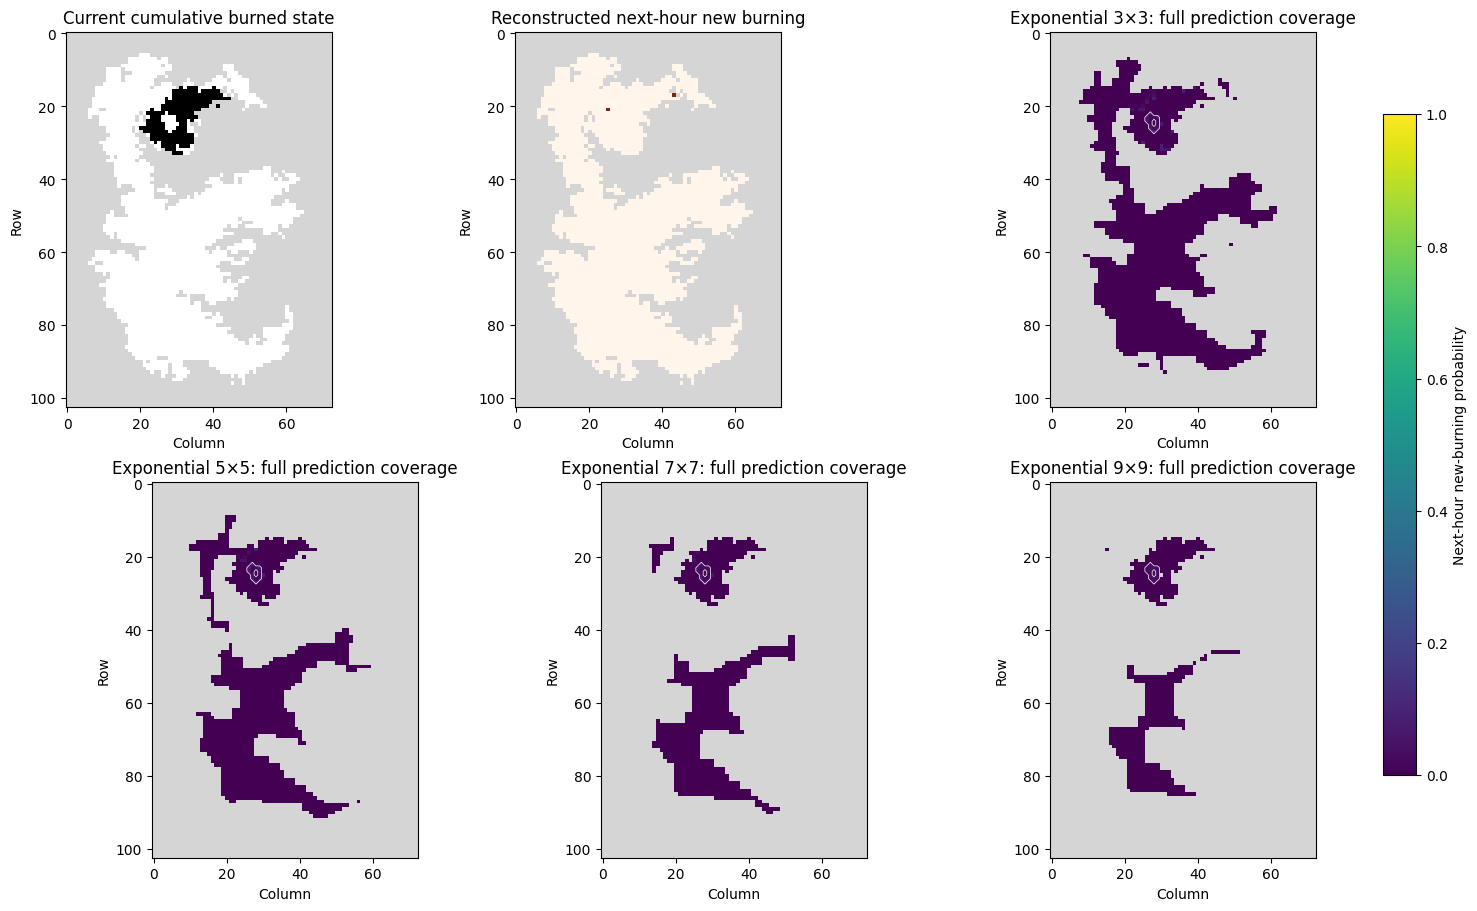

White outlines mark the identical shared contact-conditioned metric cohort.


In [3]:
probability_cmap = plt.get_cmap("viridis").copy()
probability_cmap.set_bad("#d5d5d5")
burned_cmap = plt.get_cmap("gray_r").copy()
burned_cmap.set_bad("#d5d5d5")
target_cmap = plt.get_cmap("Oranges").copy()
target_cmap.set_bad("#d5d5d5")
fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
axes = axes.ravel()
axes[0].imshow(np.ma.array(burned, mask=~burned_valid), cmap=burned_cmap, vmin=0, vmax=1)
axes[0].set_title("Current cumulative burned state")
axes[1].imshow(np.ma.array(target, mask=~arrival_valid), cmap=target_cmap, vmin=0, vmax=1)
axes[1].set_title("Reconstructed next-hour new burning")
for ax, k in zip(axes[2:], KERNELS):
    image = ax.imshow(np.ma.array(probability[k], mask=~prediction_valid[k]),
                      cmap=probability_cmap, vmin=0, vmax=1)
    ax.set_title(f"Exponential {k}×{k}: full prediction coverage")
    ax.contour(shared, levels=[0.5], colors="white", linewidths=0.5)
for ax in axes:
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
fig.colorbar(image, ax=axes[2:].tolist(), label="Next-hour new-burning probability", shrink=0.8)
plt.show()
print("White outlines mark the identical shared contact-conditioned metric cohort.")

A complete all-unburned source neighborhood is supported at inference. The following independent input check verifies exact zeros at interior targets. It also verifies that the metric cohort does not contain these zero-contact targets. Unknown source or environmental values remain unknown and are not filled with zeros.

In [4]:
for k, model in models.items():
    no_fire = torch.zeros_like(sample["burned_area"])
    check = model.predict_details(no_fire, sample["features"],
                                  channel_names=sample["channel_names"],
                                  burned_area_valid=sample["burned_area_valid"],
                                  feature_valid=sample["feature_valid"])
    known = check.valid
    assert known.any()
    assert torch.all(check.probability[known] == 0)
    assert np.all(neighbor_count[k][cohorts[k]] > 0)
print("Verified: no-contact prediction is supported; every scored target has burned-neighbor contact.")

Verified: no-contact prediction is supported; every scored target has burned-neighbor contact.
